## Clone Github project

In [1]:
import os

os.chdir("/kaggle/working")

REPO_URL = "https://github.com/Aaidaro/CoNLL-2003-NER-with-BiRNN--BiLSTM--and-BiGRU.git"
REPO_DIR = "/kaggle/working/CoNLL-2003-NER-with-BiRNN--BiLSTM--and-BiGRU"

!rm -rf "$REPO_DIR"
!git clone "$REPO_URL"

os.chdir(REPO_DIR)
print("Current directory:", os.getcwd())
!ls

Cloning into 'CoNLL-2003-NER-with-BiRNN--BiLSTM--and-BiGRU'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 25 (delta 1), reused 25 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 15.92 KiB | 3.18 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Current directory: /kaggle/working/CoNLL-2003-NER-with-BiRNN--BiLSTM--and-BiGRU
' (2).gitignore'   data      models	 requirements.txt   utils
 config		   LICENSE   README.md	 scripts


In [ ]:
!python -m pip install -q --upgrade pip
!python -m pip install -q datasets scikit-learn matplotlib pyyaml tqdm

In [3]:
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.10.0+cpu
CUDA available: False
Running on CPU


In [4]:
from pathlib import Path

loader_path = Path("data/data_loader.py")
text = loader_path.read_text(encoding="utf-8")

if 'revision="convert/parquet"' in text or "revision='convert/parquet'" in text:
    print("OK: data loader uses the Parquet revision.")
else:
    print("WARNING: Parquet revision not found. Patching loader now...")
    text = text.replace(
        'load_dataset(dataset_name, trust_remote_code=True)',
        'load_dataset(dataset_name, revision="convert/parquet")'
    )
    text = text.replace(
        "load_dataset(dataset_name, trust_remote_code=True)",
        'load_dataset(dataset_name, revision="convert/parquet")'
    )
    loader_path.write_text(text, encoding="utf-8")
    print("Patched data/data_loader.py")

Patched data/data_loader.py


In [5]:
!python scripts/main.py --full-data

Using device: cpu
conll2003/train/0000.parquet: 100%|█████████| 1.23M/1.23M [00:01<00:00, 663kB/s]
0000.parquet: 100%|██████████████████████████| 312k/312k [00:00<00:00, 7.42MB/s]
0000.parquet: 100%|██████████████████████████| 283k/283k [00:00<00:00, 6.10MB/s]
Generating train split: 14041 examples [00:00, 224210.39 examples/s]
Generating validation split: 3250 examples [00:00, 301842.03 examples/s]
Generating test split: 3453 examples [00:00, 315408.59 examples/s]

=== Dataset analysis ===
Splits: {'train': 14041, 'validation': 3250, 'test': 3453}
Columns/features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags']
Feature schema: {'id': Value('string'), 'tokens': List(Value('string')), 'pos_tags': List(ClassLabel(names=['"', "''", '#', '$', '(', ')', ',', '.', ':', '``', 'CC', 'CD', 'DT', 'EX', 'FW', 'IN', 'JJ', 'JJR', 'JJS', 'LS', 'MD', 'NN', 'NNP', 'NNPS', 'NNS', 'NN|SYM', 'PDT', 'POS', 'PRP', 'PRP$', 'RB', 'RBR', 'RBS', 'RP', 'SYM', 'TO', 'UH', 'VB', 'VBD', 'VBG', 'VBN', 'VBP'

In [ ]:
from pathlib import Path
import sys
import torch
import yaml
import pandas as pd

PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data.data_loader import create_dataloaders
from models.model import SequenceTagger

def count_parameters(model):
    """Return total and trainable parameter counts."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


with open("config/config.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)


config["data"]["use_subset"] = False

data_bundle = create_dataloaders(config)

rows = []

for model_type in ["rnn", "lstm", "gru"]:
    model = SequenceTagger(
        vocab_size=data_bundle.vocab.size(),
        num_labels=len(data_bundle.label_names),
        embedding_size=int(config["model"]["embedding_size"]),
        hidden_size=int(config["model"]["hidden_size"]),
        padding_idx=data_bundle.vocab.pad_id,
        rnn_type=model_type,
        dropout=float(config["model"].get("dropout", 0.1)),
    )

    total_params, trainable_params = count_parameters(model)

    rows.append({
        "model": model_type.upper(),
        "vocab_size_full_data": data_bundle.vocab.size(),
        "num_labels": len(data_bundle.label_names),
        "embedding_size": int(config["model"]["embedding_size"]),
        "hidden_size": int(config["model"]["hidden_size"]),
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
    })

param_df = pd.DataFrame(rows)
param_df

,model,vocab_size_full_data,num_labels,embedding_size,hidden_size,total_parameters,trainable_parameters
0,RNN,4917,9,64,64,332489,332489
1,LSTM,4917,9,64,64,382409,382409
2,GRU,4917,9,64,64,365769,365769


In [7]:
param_csv_path = "/kaggle/working/full_data_model_parameter_counts.csv"
param_df.to_csv(param_csv_path, index=False)

print("Saved:", param_csv_path)
param_df

Saved: /kaggle/working/full_data_model_parameter_counts.csv


,model,vocab_size_full_data,num_labels,embedding_size,hidden_size,total_parameters,trainable_parameters
0,RNN,4917,9,64,64,332489,332489
1,LSTM,4917,9,64,64,382409,382409
2,GRU,4917,9,64,64,365769,365769


In [8]:
from pathlib import Path

folders = [
    "outputs",
    "outputs/plots",
    "outputs/reports",
    "models/saved_models",
]

for folder in folders:
    path = Path(folder)
    print(f"\n{folder}:")
    if path.exists():
        for item in sorted(path.glob("*")):
            print(" -", item)
    else:
        print("Folder does not exist.")


outputs:
 - outputs/plots
 - outputs/reports

outputs/plots:
 - outputs/plots/gru_curves.png
 - outputs/plots/lstm_curves.png
 - outputs/plots/rnn_curves.png

outputs/reports:
 - outputs/reports/gru_classification_report.txt
 - outputs/reports/lstm_classification_report.txt
 - outputs/reports/rnn_classification_report.txt

models/saved_models:
 - models/saved_models/gru_ner.pt
 - models/saved_models/lstm_ner.pt
 - models/saved_models/rnn_ner.pt


outputs/plots/gru_curves.png


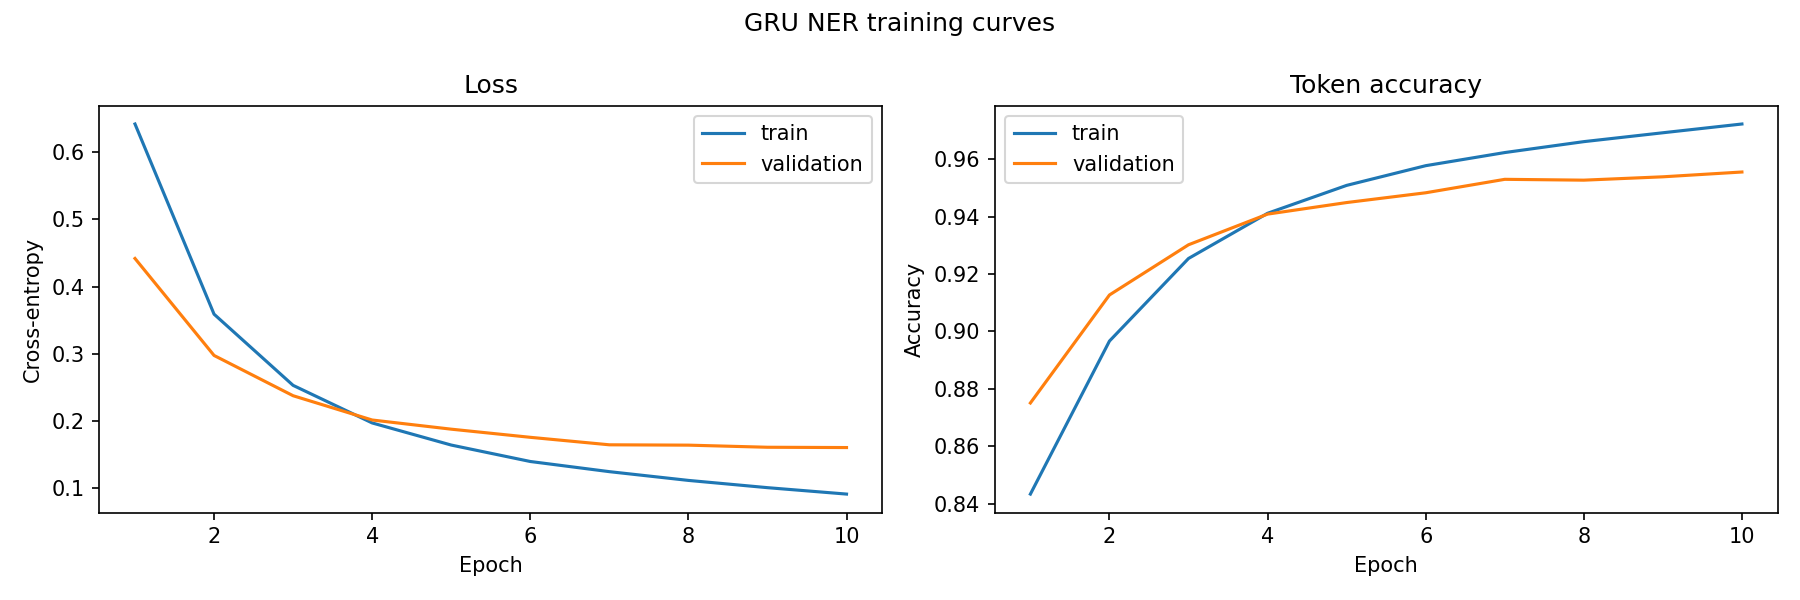

outputs/plots/lstm_curves.png


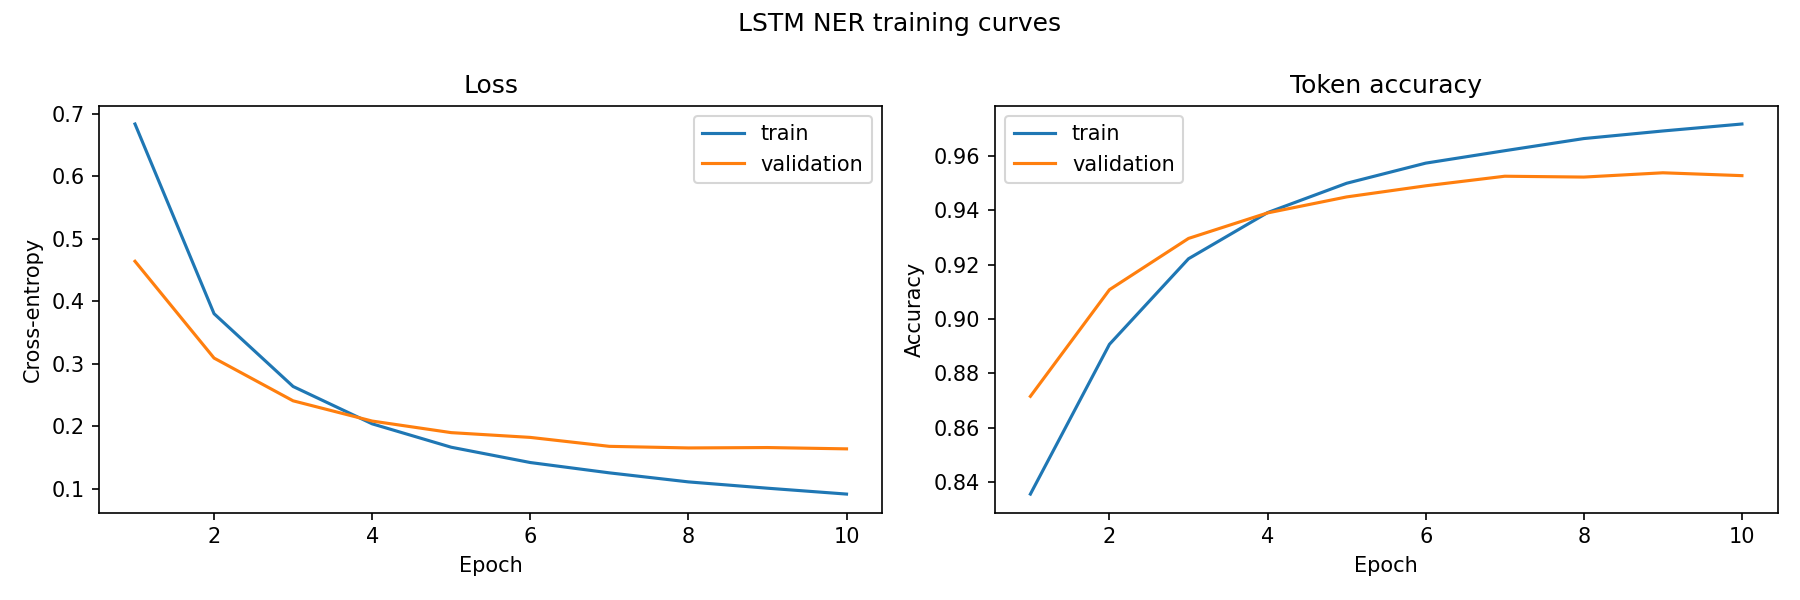

outputs/plots/rnn_curves.png


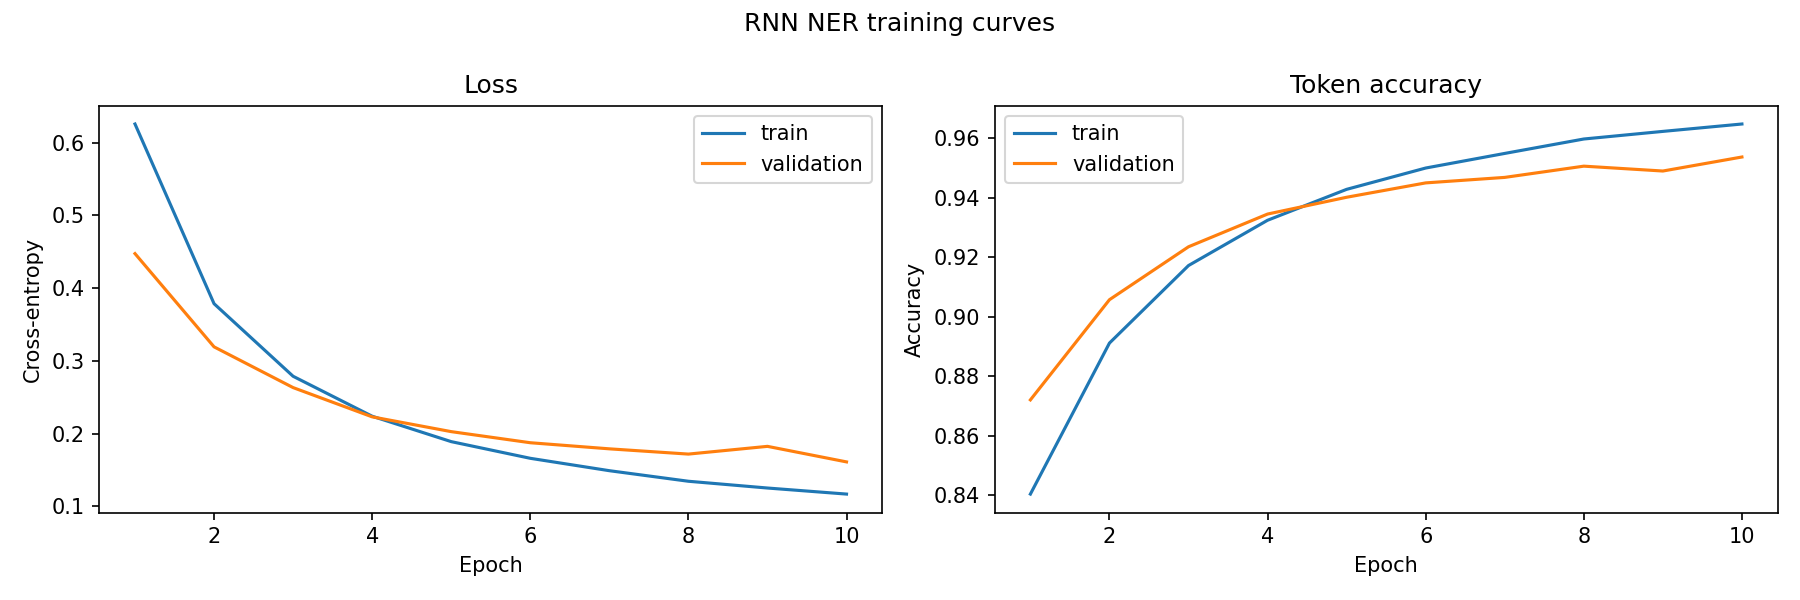

In [9]:
from pathlib import Path
from IPython.display import Image, display

plot_dir = Path("outputs/plots")

if plot_dir.exists():
    for plot_path in sorted(plot_dir.glob("*.png")):
        print(plot_path)
        display(Image(filename=str(plot_path)))
else:
    print("No plots found.")

In [10]:
from pathlib import Path

report_dir = Path("outputs/reports")

if report_dir.exists():
    for report_path in sorted(report_dir.glob("*.txt")):
        print("=" * 100)
        print(report_path)
        print("=" * 100)
        print(report_path.read_text(encoding="utf-8"))
else:
    print("No reports found.")

outputs/reports/gru_classification_report.txt
              precision    recall  f1-score   support

           O       0.97      0.99      0.98     42759
       B-PER       0.86      0.82      0.84      1842
       I-PER       0.91      0.83      0.87      1307
       B-ORG       0.79      0.74      0.77      1341
       I-ORG       0.79      0.76      0.77       751
       B-LOC       0.93      0.79      0.86      1837
       I-LOC       0.91      0.77      0.84       257
      B-MISC       0.91      0.73      0.81       922
      I-MISC       0.88      0.62      0.73       346

    accuracy                           0.96     51362
   macro avg       0.88      0.78      0.83     51362
weighted avg       0.95      0.96      0.95     51362

outputs/reports/lstm_classification_report.txt
              precision    recall  f1-score   support

           O       0.97      0.99      0.98     42759
       B-PER       0.91      0.74      0.82      1842
       I-PER       0.92      0.83      

In [11]:
import shutil
from pathlib import Path

zip_base = "/kaggle/working/conll2003_ner_full_data_outputs"
zip_path = zip_base + ".zip"

Path(zip_path).unlink(missing_ok=True)

!mkdir -p /kaggle/working/export_outputs
!rm -rf /kaggle/working/export_outputs/*

!cp -r outputs /kaggle/working/export_outputs/outputs
!cp -r models/saved_models /kaggle/working/export_outputs/saved_models
!cp /kaggle/working/full_data_model_parameter_counts.csv /kaggle/working/export_outputs/full_data_model_parameter_counts.csv

shutil.make_archive(zip_base, "zip", "/kaggle/working/export_outputs")

print("Created:", zip_path)

Created: /kaggle/working/conll2003_ner_full_data_outputs.zip


In [12]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/conll2003_ner_full_data_outputs.zip"))

/kaggle/working/conll2003_ner_full_data_outputs.zip